# A/B analysis on the Criteo Uplift benchmark: workflow, findings and pitfalls

Author: Anastasia Kalugina

## 1. Goal

Run a complete A/B-test workflow on Criteo Uplift v2.1: sample ratio check,
covariate balance, ad delivery, the pre-registered test (z-test, bootstrap,
CUPED), a post-hoc sensitivity analysis, segments, and a careful reading.

**What this notebook is, and is not.** The released data is a *benchmark sample*:
Criteo deliberately distorted the incrementality level and re-sampled every
underlying test to a common treatment ratio. The numbers therefore illustrate
**methods**; they are not a measurement of how effective Criteo ads are. The key
finding of the analysis is exactly this: the balance check shows that treatment is
**not independent of the features** in the released sample, so the naive
difference between groups depends on how one adjusts for them (section 7).

Every printed "Takeaway" line is computed from the results.

## 2. Data

Criteo Uplift Prediction Dataset v2.1, one row per user: 12 hashed or anonymised
features, `treatment`, outcomes `visit`, `conversion`, `exposure`. Licence
CC BY-NC-SA 4.0 (see `DATA_LICENSE.md`). Citation: Diemert, Betlei, Renaudin,
Amini. *A Large Scale Benchmark for Uplift Modeling*. AdKDD 2018.

What the sources say about the data (read this first):

- Dataset page: "the data has been sub-sampled non-uniformly so that the original
  incrementality level cannot be deduced from the dataset"
  (https://ailab.criteo.com/criteo-uplift-prediction-dataset/).
- Paper (arXiv:2111.10106, section 3): all incrementality tests were sub-sampled
  "at the same, global treatment ratio" (85%), and "non-uniform negative sampling
  on labels has been performed".
- Paper, Table 2: **f0, f2, f7, f10 are continuous; f1, f3, f4, f5, f6, f8, f9,
  f11 are hashed categorical features.** Their numeric values are codes, not
  quantities.

Group counts come from SQL; row-level data is loaded only where needed (three or
six columns), never the full table.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats as sps

ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()
)
sys.path.insert(0, str(ROOT / "src"))

from pa import config, stats  # noqa: E402
from pa.data import register_criteo, register_segment  # noqa: E402
from pa.db import connect, run_sql  # noqa: E402

SEED = config.SEED
ALPHA = config.ALPHA
np.random.seed(SEED)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.6f}".rstrip("0").rstrip("."))
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

if not config.CRITEO_PARQUET.exists():
    raise SystemExit("Run `python -m pa.data download` and `python -m pa.data build`")
if not config.DESIGN_FILE.exists():
    raise SystemExit("Run notebook 02 first: it writes docs/preregistration.json")
design = json.loads(config.DESIGN_FILE.read_text())
FEATURE = design["cuped_feature"]
CONT = ["f0", "f2", "f7", "f10"]
CAT = ["f1", "f3", "f4", "f5", "f6", "f8", "f9", "f11"]
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
con = connect()
register_criteo(con)
register_segment(con, FEATURE)
print("pre-registered feature (CUPED and segments):", FEATURE)

pre-registered feature (CUPED and segments): f0


## 3. Checks before reading the outcome

### 3.1 Sample ratio mismatch (SRM)
Pre-registered as an informative check with a stop rule at 1 percentage point.
For this dataset it is **not informative**: Criteo re-sampled every test to a global
85% treatment ratio, so the split is forced and the check cannot detect broken
randomisation. The numbers are reported anyway. Source:
[`sql/ab/01_group_sizes.sql`](../sql/ab/01_group_sizes.sql).

In [2]:
sizes = run_sql(con, "ab/01_group_sizes").set_index("treatment")
N_C, N_T = int(sizes.n[0]), int(sizes.n[1])
srm = stats.srm_check(N_C, N_T, config.EXPECTED_TREATMENT_SHARE)
print(sizes)
print(f"\nusers: {N_C + N_T:,}")
print(f"observed treatment share: {srm.observed_share:.7f}")
print(f"chi2 = {srm.chi2:.3f}, p = {stats.format_p(srm.p_value)}")
deviation = abs(srm.observed_share - srm.expected_share)
limit = design["srm_stop_deviation"]
print(f"deviation from 0.85: {deviation:.5%} points; stop rule at {limit:.2%}")
if deviation > limit:
    raise RuntimeError("SRM stop rule triggered; investigate before reading outcomes.")
print(
    "Takeaway: the share is 0.85 almost exactly, which is what forced re-sampling "
    "produces. This says nothing about whether randomisation held (see 3.2)."
)

                  n  share
treatment                 
0           2096937   0.15
1          11882655   0.85

users: 13,979,592
observed treatment share: 0.8500001
chi2 = 0.000, p = 0.999
deviation from 0.85: 0.00001% points; stop rule at 1.00%
Takeaway: the share is 0.85 almost exactly, which is what forced re-sampling produces. This says nothing about whether randomisation held (see 3.2).


### 3.2 Covariate balance: is treatment independent of the features?
In a clean randomised test the pre-treatment features look the same in both groups.
Two different tools are needed because of the feature types:

- **Continuous features (f0, f2, f7, f10):** standardised mean difference (SMD)
  and the z statistic of the difference in means. Sources:
  [`sql/ab/03_covariate_balance.sql`](../sql/ab/03_covariate_balance.sql).
- **Categorical features (8):** means are meaningless for hashed codes, so we test
  independence of treatment and category with a chi-square test and report
  Cramer's V as an effect size. Source:
  [`sql/ab/05_strata_counts.sql`](../sql/ab/05_strata_counts.sql).
- The pre-registered feature f0 is also split into quartiles to look at the
  treatment share directly ([`sql/ab/04_segment_metrics.sql`](../sql/ab/04_segment_metrics.sql)).

With 14 million users even tiny differences give huge z and chi-square values, so
the effect sizes (SMD, Cramer's V, share differences) matter more than p-values.

In [3]:
bal = run_sql(con, "ab/03_covariate_balance").set_index("treatment")
rows = []
for f in CONT:
    m_c, m_t = bal.loc[0, f"{f}_mean"], bal.loc[1, f"{f}_mean"]
    sd_c, sd_t = bal.loc[0, f"{f}_sd"], bal.loc[1, f"{f}_sd"]
    se = np.sqrt(sd_c**2 / bal.n[0] + sd_t**2 / bal.n[1])
    rows.append(
        {
            "feature": f,
            "mean_control": m_c,
            "mean_treatment": m_t,
            "smd": stats.smd(m_c, m_t, sd_c, sd_t),
            "z": (m_t - m_c) / se,
        }
    )
smd_table = pd.DataFrame(rows)
smd_table

,feature,mean_control,mean_treatment,smd,z
0,f0,19.651705,19.614755,-0.006866,-9.158571
1,f2,8.448173,8.446302,-0.006241,-8.316597
2,f7,5.080284,5.105555,0.02127,28.816554
3,f10,5.331898,5.33366,0.010563,14.227987


Chi-square test of independence between treatment and category for each categorical feature.

In [4]:
strata = run_sql(con, "ab/05_strata_counts")
rows = []
for f in CAT:
    tab = (
        strata[strata.feature == f]
        .pivot(index="category", columns="treatment", values="n")
        .fillna(0)
        .to_numpy()
    )
    chi2, p, dof, _ = sps.chi2_contingency(tab, correction=False)
    rows.append(
        {
            "feature": f,
            "categories": tab.shape[0],
            "chi2": chi2,
            "dof": dof,
            "p_value": stats.format_p(p),
            "cramers_v": stats.cramers_v(chi2, tab.sum(), *tab.shape),
            "p_raw": p,
        }
    )
cat_table = pd.DataFrame(rows)
cat_table.drop(columns="p_raw")

,feature,categories,chi2,dof,p_value,cramers_v
0,f1,60,"1,125.329515",59,6.74e-197,0.008972
1,f3,552,"4,529.133767",551,< 1e-300,0.017999
2,f4,260,514.462534,259,4.66e-19,0.006066
3,f5,132,"1,732.112312",131,2.36e-277,0.011131
4,f6,1645,"4,926.692792",1644,< 1e-300,0.018773
5,f8,3743,"4,746.440953",3742,4.25e-27,0.018426
6,f9,1594,"2,476.135418",1593,1.62e-41,0.013309
7,f11,136,262.422569,135,3.26e-10,0.004333


Treatment share by quartile of the pre-registered feature, and the verdict of the balance check.

In [5]:
seg = run_sql(con, "ab/04_segment_metrics")
share_by_q = (
    seg.pivot(index="quartile", columns="treatment", values="n")
    .rename(columns={0: "n_control", 1: "n_treatment"})
    .assign(treatment_share=lambda d: d.n_treatment / (d.n_control + d.n_treatment))
)
print(f"treatment share by quartile of {FEATURE} (overall {srm.observed_share:.4f}):")
print(share_by_q)
n_reject = int((cat_table.p_raw < 0.001).sum())
print(
    f"\nTakeaway (FINDING): chi-square rejects independence of treatment and "
    f"category for {n_reject} of {len(CAT)} categorical features "
    f"(Cramer's V up to {cat_table.cramers_v.max():.4f}); for the continuous "
    f"features max |SMD| is {smd_table.smd.abs().max():.4f} "
    f"(max |z| = {smd_table.z.abs().max():.1f}); the treatment share ranges from "
    f"{share_by_q.treatment_share.min():.4f} to "
    f"{share_by_q.treatment_share.max():.4f} across quartiles of {FEATURE}."
)
print(
    "Treatment is NOT independent of the features in the released sample. "
    "A small |SMD| does not rescue this: with 14M users z is large, and the "
    "categorical features are the ones that matter."
)

treatment share by quartile of f0 (overall 0.8500):
treatment  n_control  n_treatment  treatment_share
quartile                                          
1             571784      3133761         0.845695
2             468349      2815902         0.857395
3             526737      2968163         0.849284
4             530067      2964829         0.848331

Takeaway (FINDING): chi-square rejects independence of treatment and category for 8 of 8 categorical features (Cramer's V up to 0.0188); for the continuous features max |SMD| is 0.0213 (max |z| = 28.8); the treatment share ranges from 0.8457 to 0.8574 across quartiles of f0.
Treatment is NOT independent of the features in the released sample. A small |SMD| does not rescue this: with 14M users z is large, and the categorical features are the ones that matter.


Figure: treatment share by f0 quartile and Cramer's V per categorical feature.

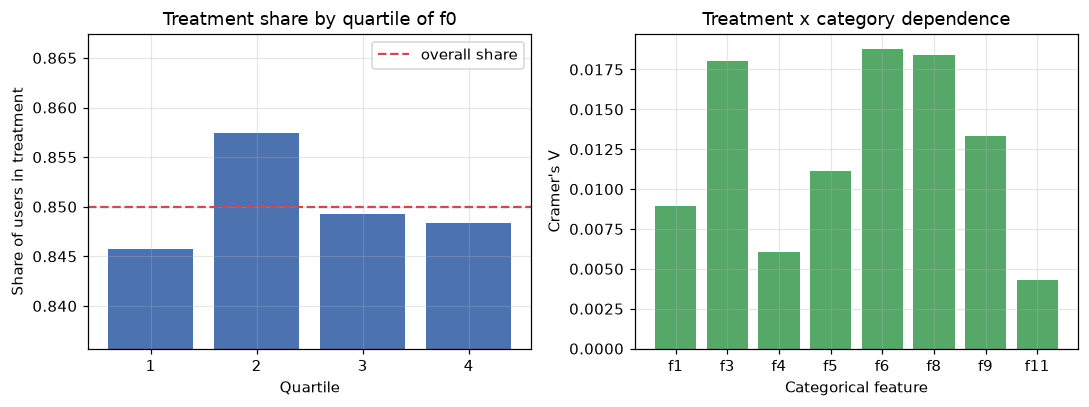

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].bar(share_by_q.index.astype(str), share_by_q.treatment_share, color="#4c72b0")
axes[0].axhline(srm.observed_share, color="#c44e52", ls="--", label="overall share")
axes[0].set_ylim(
    share_by_q.treatment_share.min() - 0.01, share_by_q.treatment_share.max() + 0.01
)
axes[0].set_title(f"Treatment share by quartile of {FEATURE}")
axes[0].set_xlabel("Quartile")
axes[0].set_ylabel("Share of users in treatment")
axes[0].legend()
axes[1].bar(cat_table.feature, cat_table.cramers_v, color="#55a868")
axes[1].set_title("Treatment x category dependence")
axes[1].set_xlabel("Categorical feature")
axes[1].set_ylabel("Cramer's V")
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "criteo_covariate_balance.png", dpi=130)
plt.show()

### 3.3 Did the ads reach people? (exposure)
`exposure` is the share of users who actually saw an ad (the dataset describes it as
effective exposure). In the treatment group it shows how much of the assignment turned
into delivery; in control it should be about zero. Source:
[`sql/ab/02_group_metrics.sql`](../sql/ab/02_group_metrics.sql). Note that this share
comes from the sub-sampled data.

In [7]:
gm = run_sql(con, "ab/02_group_metrics").set_index("treatment")
print(gm)
E_T = gm.exposed[1] / gm.n[1]
E_C = gm.exposed[0] / gm.n[0]
print(f"\nexposure rate: treatment {E_T:.4%}, control {E_C:.4%}")
print(
    f"Takeaway: {E_T:.2%} of treated users have exposure = 1; the rest were "
    "eligible but, per this column, were not exposed."
)

                  n  visits  conversions  exposed   n_v0_c0  n_v1_c0  n_v1_c1  n_v0_c1
treatment                                                                             
0           2096937  80,105        4,063        0   2016832    76042     4063        0
1          11882655 576,824       36,711  428,212  11305831   540113    36711        0

exposure rate: treatment 3.6037%, control 0.0000%
Takeaway: 3.60% of treated users have exposure = 1; the rest were eligible but, per this column, were not exposed.


## 4. Pre-registered analysis: naive ITT on visit

The pre-registered estimand is the difference in visit rates between treatment and
control (intention-to-treat), tested with a two-proportion z-test: pooled standard
error for the p-value, unpooled for the interval. A bootstrap (multinomial
resampling of the four visit x conversion cells, 2000 draws, seed 42) checks the
interval.

**Reading it correctly:** because treatment is not independent of the features
(section 3.2), this "naive" difference is not a clean causal estimate in this
sample. It is reported because it was pre-registered; section 7 shows how much it
moves under adjustment.

In [8]:
n_c, n_t = int(gm.n[0]), int(gm.n[1])
primary = stats.proportion_test(
    int(gm.visits[0]), n_c, int(gm.visits[1]), n_t, alpha=ALPHA
)
CELLS = ["n_v0_c0", "n_v1_c0", "n_v1_c1", "n_v0_c1"]
boot = stats.bootstrap_cells(
    gm.loc[0, CELLS].to_numpy(),
    gm.loc[1, CELLS].to_numpy(),
    "visit",
    n_boot=design["n_boot"],
    seed=SEED,
    alpha=ALPHA,
)
print(
    f"visit rate: control {primary.mean_control:.4%}, "
    f"treatment {primary.mean_treatment:.4%}"
)
print(
    f"absolute difference: {primary.abs_diff:.4%} points "
    f"(95% CI {primary.ci_low:.4%} .. {primary.ci_high:.4%})"
)
print(f"relative difference: {primary.rel_diff:.2%}")
print(f"z = {primary.z:.1f}, p = {stats.format_p(primary.p_value)}")
print(f"bootstrap 95% CI: {boot.ci_low:.4%} .. {boot.ci_high:.4%}")

visit rate: control 3.8201%, treatment 4.8543%
absolute difference: 1.0342% points (95% CI 1.0056% .. 1.0629%)
relative difference: 27.07%
z = 65.2, p = < 1e-300
bootstrap 95% CI: 1.0039% .. 1.0619%


Reading of the primary result: standard error, MDE and bootstrap agreement relative to the standard error.

In [9]:
se_visit = (primary.ci_high - primary.ci_low) / (2 * 1.96)
gap_lo = abs(boot.ci_low - primary.ci_low) / se_visit
gap_hi = abs(boot.ci_high - primary.ci_high) / se_visit
mde_visit = stats.mde_proportion(primary.mean_control, n_c, n_t, alpha=ALPHA)
print(
    f"Takeaway: the naive visit difference is {primary.abs_diff:.3%} points with "
    f"standard error {se_visit:.4%}; the minimum detectable lift was "
    f"{mde_visit:.3%} points."
)
print(
    f"Bootstrap and analytical interval ends differ by {gap_lo:.3f} and {gap_hi:.3f} "
    f"standard errors; agreement within 0.2 SE: {max(gap_lo, gap_hi) < 0.2}"
)
print(
    "(Tolerance 0.2 SE: the Monte Carlo error of a 2.5% bootstrap quantile with "
    "2000 draws is about 0.06 SE, so 0.2 SE is roughly three such errors.)"
)
print(
    "The small standard error describes sampling noise only. It says nothing about "
    "bias from the imbalance found in 3.2."
)

Takeaway: the naive visit difference is 1.034% points with standard error 0.0146%; the minimum detectable lift was 0.040% points.
Bootstrap and analytical interval ends differ by 0.113 and 0.070 standard errors; agreement within 0.2 SE: True
(Tolerance 0.2 SE: the Monte Carlo error of a 2.5% bootstrap quantile with 2000 draws is about 0.06 SE, so 0.2 SE is roughly three such errors.)
The small standard error describes sampling noise only. It says nothing about bias from the imbalance found in 3.2.


## 5. CUPED with the pre-registered covariate (labelled: pre-registered)

CUPED subtracts the part of the outcome predicted by a pre-treatment variable.
The pre-registered covariate is **f0** (chosen in notebook 02 by correlation with
`visit` in control).

Honest note: the pre-registration rule had two flaws. It coupled the CUPED covariate
with the segmentation feature, and it treated hashed categorical features as numbers.
f0 happens to be continuous, so this particular result is valid as a variance
reduction attempt, but the rule was not sound. CUPED also removes only the variance
explained by the covariate (about its squared correlation), and it does not fix
bias from imbalance. The adjustments that address imbalance are in section 7.

In [10]:
arr = con.execute(f"SELECT treatment, visit, {FEATURE} AS x FROM criteo").fetchnumpy()
t = arr["treatment"]
y = arr["visit"].astype(np.float64)
res = stats.cuped(y, arr["x"])
raw = stats.mean_diff_test(y[t == 0], y[t == 1], alpha=ALPHA)
adj = stats.mean_diff_test(res.y_adj[t == 0], res.y_adj[t == 1], alpha=ALPHA)
width_raw = raw.ci_high - raw.ci_low
width_adj = adj.ci_high - adj.ci_low
print(f"theta = {res.theta:.5f}, variance reduction = {res.variance_reduction:.4%}")
print(f"without CUPED: {raw.abs_diff:.4%}, CI {raw.ci_low:.4%} .. {raw.ci_high:.4%}")
print(f"with CUPED:    {adj.abs_diff:.4%}, CI {adj.ci_low:.4%} .. {adj.ci_high:.4%}")
print(f"interval width ratio (CUPED / raw): {width_adj / width_raw:.4f}")
del arr, y, res

theta = -0.00527, variance reduction = 1.7965%
without CUPED: 1.0342%, CI 1.0056% .. 1.0629%
with CUPED:    1.0148%, CI 0.9863% .. 1.0432%
interval width ratio (CUPED / raw): 0.9932


Reading of the CUPED result.

In [11]:
shift = abs(adj.abs_diff - raw.abs_diff)
print(
    f"Takeaway: the interval width changes to {width_adj / width_raw:.2%} of the "
    f"original; the estimate moves by {shift:.4%} points."
)
print(
    "Do not read this as a CUPED success: a point estimate that moves while the "
    "interval barely shrinks is not explained by this analysis, "
    "and it is not extra precision."
    if shift > 0.1 * se_visit
    else "The estimate is stable; the gain in precision is what the table shows."
)

Takeaway: the interval width changes to 99.32% of the original; the estimate moves by 0.0195% points.
Do not read this as a CUPED success: a point estimate that moves while the interval barely shrinks is not explained by this analysis, and it is not extra precision.


## 6. Secondary metric and guardrail

Conversion is tested like the primary metric; its p-value goes into the Holm family
in section 9. The guardrail "conversion given visit" is **descriptive only**: it
keeps only users who visited, and a visit is itself an outcome of the treatment, so
the two groups of visitors are no longer comparable by randomisation.

In [12]:
conv = stats.proportion_test(
    int(gm.conversions[0]), n_c, int(gm.conversions[1]), n_t, alpha=ALPHA
)
conv_boot = stats.bootstrap_cells(
    gm.loc[0, CELLS].to_numpy(),
    gm.loc[1, CELLS].to_numpy(),
    "conversion",
    n_boot=design["n_boot"],
    seed=SEED,
    alpha=ALPHA,
)
print(
    f"conversion rate: control {conv.mean_control:.4%}, "
    f"treatment {conv.mean_treatment:.4%}"
)
print(
    f"absolute difference: {conv.abs_diff:.5%} points "
    f"(95% CI {conv.ci_low:.5%} .. {conv.ci_high:.5%})"
)
print(
    f"relative difference: {conv.rel_diff:.2%}, z = {conv.z:.1f}, "
    f"raw p = {stats.format_p(conv.p_value)}"
)
print(f"bootstrap 95% CI: {conv_boot.ci_low:.5%} .. {conv_boot.ci_high:.5%}")

conversion rate: control 0.1938%, treatment 0.3089%
absolute difference: 0.11519% points (95% CI 0.10845% .. 0.12192%)
relative difference: 59.45%, z = 28.5, raw p = 7.31e-179
bootstrap 95% CI: 0.10838% .. 0.12224%


The guardrail: conversion among users who visited (descriptive only).

In [13]:
visitors_c = int(gm.n_v1_c0[0] + gm.n_v1_c1[0])
visitors_t = int(gm.n_v1_c0[1] + gm.n_v1_c1[1])
guard = stats.proportion_test(
    int(gm.n_v1_c1[0]), visitors_c, int(gm.n_v1_c1[1]), visitors_t, alpha=ALPHA
)
print("GUARDRAIL (descriptive only, conditions on visit):")
print(f"  visitors: control {visitors_c:,}, treatment {visitors_t:,}")
print(
    f"  conversion given visit: control {guard.mean_control:.3%}, "
    f"treatment {guard.mean_treatment:.3%}"
)
print(f"  difference {guard.abs_diff:.3%} points (no inference drawn)")

GUARDRAIL (descriptive only, conditions on visit):
  visitors: control 80,105, treatment 576,824
  conversion given visit: control 5.072%, treatment 6.364%
  difference 1.292% points (no inference drawn)


## 7. Post-hoc sensitivity analysis (NOT pre-registered)

Section 3.2 showed that treatment depends on the features. If features also predict
visits (they do: that was the reason to use them for CUPED), the naive difference
mixes the effect of treatment with differences in who got treated. We cannot
remove this bias without knowing the assignment mechanism, but we can ask how much
the estimate moves under reasonable adjustments:

- **Post-stratification** by each hashed categorical feature separately, and by
  quartiles of f0: compare treated and control inside each stratum, then average
  with stratum-size weights. Strata with no control or no treated users are
  dropped and the share of users that remains (coverage) is reported.
- **Linear adjustment** (OLS with robust standard errors) on the four continuous
  features f0, f2, f7, f10.
- **Odds ratio:** crude versus Mantel-Haenszel stratified, as a scale-free check.

Sources: [`sql/ab/05_strata_counts.sql`](../sql/ab/05_strata_counts.sql) and
[`sql/ab/04_segment_metrics.sql`](../sql/ab/04_segment_metrics.sql).

In [14]:
def pivot_strata(df, index):
    p = df.pivot(index=index, columns="treatment", values=["n", "visits"]).fillna(0)
    return p["n"][0], p["visits"][0], p["n"][1], p["visits"][1]


def sens_row(label, df, index):
    n_c_, x_c_, n_t_, x_t_ = pivot_strata(df, index)
    r = stats.poststratified_diff(n_c_, x_c_, n_t_, x_t_, alpha=ALPHA)
    return {
        "method": label,
        "lift_pp": r.abs_diff * 100,
        "ci_low_pp": r.ci_low * 100,
        "ci_high_pp": r.ci_high * 100,
        "coverage_pct": r.coverage * 100,
        "strata_used": f"{r.n_strata_used}/{r.n_strata_total}",
        "mh_odds_ratio": stats.mantel_haenszel_or(n_c_, x_c_, n_t_, x_t_),
    }


rows = [
    {
        "method": "naive (pre-registered)",
        "lift_pp": primary.abs_diff * 100,
        "ci_low_pp": primary.ci_low * 100,
        "ci_high_pp": primary.ci_high * 100,
        "coverage_pct": 100.0,
        "strata_used": "-",
        "mh_odds_ratio": stats.crude_odds_ratio(n_c, gm.visits[0], n_t, gm.visits[1]),
    }
]
for f in CAT:
    rows.append(
        sens_row(f"post-stratified by {f}", strata[strata.feature == f], "category")
    )
rows.append(sens_row(f"post-stratified by {FEATURE} quartiles", seg, "quartile"))

Linear adjustment on the four continuous features (OLS, robust standard errors), then the full sensitivity table.

In [15]:
cols = ", ".join(CONT)
d = con.execute(f"SELECT visit, treatment, {cols} FROM criteo").fetchnumpy()
X = np.column_stack([d[f] for f in CONT])
beta, se_beta = stats.ols_effect(d["visit"], d["treatment"], X)
rows.append(
    {
        "method": "linear adjustment on f0, f2, f7, f10",
        "lift_pp": beta * 100,
        "ci_low_pp": (beta - 1.96 * se_beta) * 100,
        "ci_high_pp": (beta + 1.96 * se_beta) * 100,
        "coverage_pct": 100.0,
        "strata_used": "-",
        "mh_odds_ratio": np.nan,
    }
)
del d, X
sens = pd.DataFrame(rows)
sens

,method,lift_pp,ci_low_pp,ci_high_pp,coverage_pct,strata_used,mh_odds_ratio
0,naive (pre-registered),1.03424,1.005563,1.062918,100,-,1.28455
1,post-stratified by f1,0.991656,0.962903,1.020409,99.999285,34/60,1.270272
2,post-stratified by f3,0.890657,0.861715,0.9196,99.997003,390/552,1.232531
3,post-stratified by f4,0.977304,0.949542,1.005067,99.998391,150/260,1.292039
4,post-stratified by f5,0.97304,0.944256,1.001824,99.99882,77/132,1.2634
5,post-stratified by f6,0.927674,0.898936,0.956413,99.986616,1081/1645,1.246605
6,post-stratified by f8,0.787712,0.761881,0.813543,99.97188,2345/3743,1.284458
7,post-stratified by f9,0.802861,0.776905,0.828817,99.988505,1003/1594,1.287509
8,post-stratified by f11,1.001899,0.973915,1.029884,99.999099,72/136,1.292313
9,post-stratified by f0 quartiles,0.975374,0.946744,1.004004,100,4/4,1.265546


What the table says: range of adjusted estimates, odds ratios, coverage, sign.

In [16]:
adjusted = sens.iloc[1:]
naive_pp = sens.lift_pp.iloc[0]
print(
    f"naive difference: {naive_pp:.3f} pp; adjusted estimates range from "
    f"{adjusted.lift_pp.min():.3f} to {adjusted.lift_pp.max():.3f} pp"
)
or_adj = adjusted.mh_odds_ratio.dropna()
print(
    f"odds ratio: crude {sens.mh_odds_ratio.iloc[0]:.3f}; Mantel-Haenszel "
    f"{or_adj.min():.3f} .. {or_adj.max():.3f}"
)
print(
    f"coverage of the stratified estimates: {adjusted.coverage_pct.min():.2f}% .. "
    f"{adjusted.coverage_pct.max():.2f}% of users"
)
print(
    f"Takeaway: the sign is robust (all {len(adjusted)} adjusted estimates are "
    + ("positive" if (adjusted.ci_low_pp > 0).all() else "NOT all positive")
    + f"; the naive estimate is {naive_pp / adjusted.lift_pp.median():.2f} times the "
    "median adjusted one). The size is not identifiable: it depends on the "
    "adjustment. The 95% intervals (about +/- 0.03 pp) reflect sampling noise only, "
    "not bias."
)

naive difference: 1.034 pp; adjusted estimates range from 0.788 to 1.002 pp
odds ratio: crude 1.285; Mantel-Haenszel 1.233 .. 1.292
coverage of the stratified estimates: 99.97% .. 100.00% of users
Takeaway: the sign is robust (all 10 adjusted estimates are positive; the naive estimate is 1.09 times the median adjusted one). The size is not identifiable: it depends on the adjustment. The 95% intervals (about +/- 0.03 pp) reflect sampling noise only, not bias.


Figure: all estimates with their 95% intervals (sampling noise only).

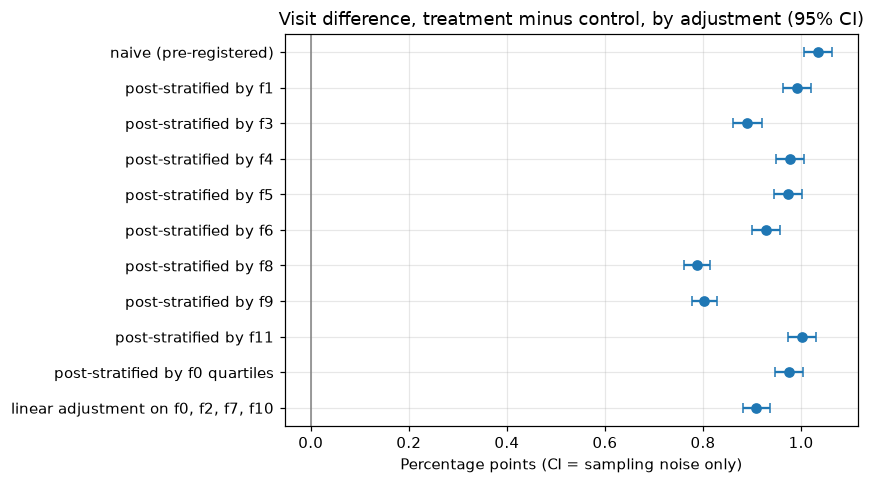

In [17]:
fig, ax = plt.subplots(figsize=(8, 4.5))
y_pos = np.arange(len(sens))[::-1]
ax.errorbar(
    sens.lift_pp,
    y_pos,
    xerr=[sens.lift_pp - sens.ci_low_pp, sens.ci_high_pp - sens.lift_pp],
    fmt="o",
    capsize=3,
)
ax.set_yticks(y_pos, labels=sens.method)
ax.axvline(0, color="grey", lw=1)
ax.set_title("Visit difference, treatment minus control, by adjustment (95% CI)")
ax.set_xlabel("Percentage points (CI = sampling noise only)")
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "criteo_sensitivity.png", dpi=130)
plt.show()

## 8. Segments by quartile of the pre-registered feature (descriptive)

Quartiles of f0 (cut points from `percentile_cont`), both outcomes. These are
**descriptive** splits, not evidence of effect heterogeneity: the treatment share
differs between quartiles (section 3.2), so differences in the raw lift between
quartiles mix real differences with differences in who was treated. The feature is
anonymised, so the segments have no business description. Quartile 1 is a point
mass at the minimum of f0 (26.5% of users share that value), so the quartiles are
defined by thresholds and are not of equal size.

In [18]:
rows = []
for q, g in seg.groupby("quartile"):
    g = g.set_index("treatment")
    for metric, col in [("visit", "visits"), ("conversion", "conversions")]:
        r = stats.proportion_test(
            int(g[col][0]), int(g.n[0]), int(g[col][1]), int(g.n[1]), alpha=ALPHA
        )
        rows.append(
            {
                "quartile": q,
                "metric": metric,
                "treatment_share": g.n[1] / (g.n[0] + g.n[1]),
                "rate_control": r.mean_control,
                "rate_treatment": r.mean_treatment,
                "abs_lift": r.abs_diff,
                "ci_low": r.ci_low,
                "ci_high": r.ci_high,
                "p_raw": r.p_value,
            }
        )
seg_table = pd.DataFrame(rows)
seg_table

,quartile,metric,treatment_share,rate_control,rate_treatment,abs_lift,ci_low,ci_high,p_raw
0,1,visit,0.845695,0.051638,0.053334,0.001696,0.00107,0.002321,0
1,1,conversion,0.845695,0.001488,0.00187,0.000381,0.000271,0.000492,0
2,2,visit,0.857395,0.076413,0.112709,0.036296,0.03545,0.037142,0
3,2,conversion,0.857395,0.00578,0.009638,0.003858,0.003613,0.004104,0
4,3,visit,0.849284,0.016164,0.018427,0.002264,0.00189,0.002637,0
5,3,conversion,0.849284,0.000609,0.000803,0.000194,0.00012,0.000268,0.000003
6,4,visit,0.848331,0.011842,0.012687,0.000845,0.000527,0.001163,0
7,4,conversion,0.848331,0.000347,0.000448,0.000101,0.000045,0.000156,0.001153


## 9. Multiple comparisons: the pre-registered Holm family

Family of 9 tests: conversion overall, visit in 4 segments, conversion in 4
segments. The primary visit test stays outside the family.

In [19]:
family = pd.concat(
    [
        pd.DataFrame(
            [
                {
                    "test": "conversion, overall",
                    "abs_lift": conv.abs_diff,
                    "p_raw": conv.p_value,
                }
            ]
        ),
        seg_table.assign(
            test=lambda d: d.metric + ", segment Q" + d.quartile.astype(str)
        )[["test", "abs_lift", "p_raw"]],
    ],
    ignore_index=True,
)
assert len(family) == design["holm_family_size"], (
    f"Holm family has {len(family)} tests, pre-registered "
    f"{design['holm_family_size']}: a quartile is empty"
)
family["p_holm"] = stats.holm(family.p_raw.to_numpy())
family["significant_after_holm"] = family.p_holm < ALPHA
family["p_holm_text"] = family.p_holm.map(stats.format_p)
family[["test", "abs_lift", "p_holm_text", "significant_after_holm"]]

,test,abs_lift,p_holm_text,significant_after_holm
0,"conversion, overall",0.001152,5.85e-178,True
1,"visit, segment Q1",0.001696,5.77e-07,True
2,"conversion, segment Q1",0.000381,2.23e-09,True
3,"visit, segment Q2",0.036296,< 1e-300,True
4,"conversion, segment Q2",0.003858,1.57e-145,True
5,"visit, segment Q3",0.002264,3.94e-29,True
6,"conversion, segment Q3",0.000194,6.31e-06,True
7,"visit, segment Q4",0.000845,1.08e-06,True
8,"conversion, segment Q4",0.000101,0.00115,True


How many of the 9 tests survive the Holm correction.

In [20]:
n_sig = int(family.significant_after_holm.sum())
print(f"Takeaway: {n_sig} of {len(family)} tests stay significant after Holm.")
if n_sig == len(family):
    print(
        "When every test is significant at this sample size, the correction adds "
        "little: it cannot separate segments from each other."
    )

Takeaway: 9 of 9 tests stay significant after Holm.
When every test is significant at this sample size, the correction adds little: it cannot separate segments from each other.


## 10. CACE: why it is not estimated here

If the control group could not see Criteo ads and assignment affected visits only
through seeing an ad (exclusion restriction), the effect on exposed users would be

CACE = ITT / (exposure rate in treatment - exposure rate in control).

No number is computed in this notebook, because the assumptions are doubtful:
exposure is adaptive and can follow a visit (bids adjust to user behaviour),
Criteo's own causal graph has an arrow from treatment to the outcome that does not go
through exposure, and the exposure share comes from sub-sampled data.

## 11. Conclusions

The summary below is produced by code from the computed values; no number is typed
by hand. How to read it:

1. The checks found that treatment is not independent of the features, so the
   naive difference is not a clean causal estimate in this sample.
2. The sign of the visit difference survives every adjustment tried; its size does
   not (section 7).
3. The tiny confidence intervals describe sampling noise, not bias.
4. CACE and any money arithmetic are deliberately not computed: the data does not
   support them.

In [21]:
summary = pd.DataFrame(
    [
        ("treatment share", f"{srm.observed_share:.7f} (forced to 0.85)"),
        (
            "treatment x category rejected (p < 0.001)",
            f"{n_reject} of {len(CAT)} categorical features",
        ),
        ("max Cramer's V", f"{cat_table.cramers_v.max():.4f}"),
        ("max |SMD| continuous", f"{smd_table.smd.abs().max():.4f}"),
        (
            f"treatment share across {FEATURE} quartiles",
            f"{share_by_q.treatment_share.min():.4f} .. "
            f"{share_by_q.treatment_share.max():.4f}",
        ),
        (
            "visit rate control / treatment",
            f"{primary.mean_control:.3%} / {primary.mean_treatment:.3%}",
        ),
        ("naive visit difference", f"{naive_pp:.3f} pp"),
        (
            "adjusted visit difference range",
            f"{adjusted.lift_pp.min():.3f} .. {adjusted.lift_pp.max():.3f} pp",
        ),
        (
            "odds ratio crude / Mantel-Haenszel range",
            f"{sens.mh_odds_ratio.iloc[0]:.3f} / "
            f"{or_adj.min():.3f} .. {or_adj.max():.3f}",
        ),
        ("CUPED (f0) interval width vs raw", f"{width_adj / width_raw:.2%}"),
        (
            "conversion p raw / Holm",
            f"{stats.format_p(conv.p_value)} / {stats.format_p(family.p_holm[0])}",
        ),
    ],
    columns=["quantity", "value"],
)
print(summary.to_string(index=False))

                                 quantity                       value
                          treatment share  0.8500001 (forced to 0.85)
treatment x category rejected (p < 0.001) 8 of 8 categorical features
                           max Cramer's V                      0.0188
                     max |SMD| continuous                      0.0213
      treatment share across f0 quartiles            0.8457 .. 0.8574
           visit rate control / treatment             3.820% / 4.854%
                   naive visit difference                    1.034 pp
          adjusted visit difference range           0.788 .. 1.002 pp
 odds ratio crude / Mantel-Haenszel range      1.285 / 1.233 .. 1.292
         CUPED (f0) interval width vs raw                      99.32%
                  conversion p raw / Holm       7.31e-179 / 5.85e-178


## 12. Limitations

- **The data is sub-sampled non-uniformly.** Dataset page: "the data has been
  sub-sampled non-uniformly so that the original incrementality level cannot be
  deduced from the dataset" (https://ailab.criteo.com/criteo-uplift-prediction-dataset/).
  The paper (arXiv:2111.10106, section 3) adds that all tests were re-sampled to one
  global treatment ratio and that labels were sampled non-uniformly. The sample is a
  benchmark for methods; it does not measure real ad effectiveness. The paper's
  Table 1 reports a relative average uplift of 68.7% (visit) and 37.2%
  (conversion) for this dataset; the paper does not define it in a way we can
  reproduce, so those figures are **not comparable** with the numbers here.
- **Treatment is not independent of the features** (section 3.2). The naive
  difference is biased by an unknown amount; adjustments change it noticeably and we
  cannot say which is right. Post-hoc analyses (section 7) were not pre-registered.
- **The data pools several tests** with no test identifier, so a pooled difference
  can hide differences between tests (Simpson's paradox).
- **Anonymised and hashed features.** Categorical codes carry no meaning;
  segments have no business description.
- **SRM is uninformative** because the 85% split was forced.
- **Huge power.** Even negligible differences are significant; sizes and
  sensitivity matter, not p-values.
- **Exposure is adaptive**, so a CACE rests on assumptions that are doubtful here
  and is not estimated.
- **No time and no costs** in the dataset.
- **The pre-registration is procedural, not blind**, and its covariate rule was
  flawed (notebook 02, section 8).

## 13. Sources

- Criteo AI Lab, Criteo Uplift Prediction Dataset v2.1:
  https://ailab.criteo.com/criteo-uplift-prediction-dataset/ (checked 2026-10-15).
- Diemert, E., Betlei, A., Renaudin, C., Amini, M.-R. A Large Scale Benchmark for
  Uplift Modeling. AdKDD 2018.
- Diemert et al. A Large Scale Benchmark for Individual Treatment Effect Prediction
  and Uplift Modeling. arXiv:2111.10106 (sections 3, Tables 1 and 2).
- Deng, A., Xu, Y., Kohavi, R., Walker, T. Improving the sensitivity of online
  controlled experiments by utilizing pre-experiment data. WSDM 2013.
- Mantel, N., Haenszel, W. Statistical aspects of the analysis of data from
  retrospective studies of disease. JNCI 22, 1959.
- Holm, S. A simple sequentially rejective multiple test procedure. Scand. J.
  Statistics 6, 1979.